# Value Investing Screener

This notebook screens S&P 500 stocks using a composite Relative Value (RV) Score
derived from fundamental ratios: P/E, P/B, P/S, EV/EBITDA, and EV/GP.

Stocks are ranked by percentile across all ratios — lower RV Score = better value.

In [7]:
import numpy as np
import pandas as pd
import requests
import time
import os
from scipy import stats
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from dotenv import load_dotenv
plt.style.use('ggplot')

load_dotenv('../../.env')
API_KEY = os.getenv('ALPHA_VANTAGE_API_KEY')
BASE_URL = 'https://www.alphavantage.co/query'
print(f'API Key loaded: {"Yes" if API_KEY else "No — create .env file with ALPHA_VANTAGE_API_KEY"}')

API Key loaded: Yes


## 1. Define Data Fetching Functions

In [8]:
def get_stock_data_alpha_vantage(symbol):
    params = {
        'function': 'OVERVIEW',
        'symbol': symbol,
        'apikey': API_KEY,
        'outputsize': 'full'
    }
    try:
        response = requests.get(BASE_URL, params=params)
        response.raise_for_status()
        data = response.json()
        if 'Note' in data or 'Error Message' in data:
            print(f'  Could not retrieve data for {symbol}: {data.get("Note") or data.get("Error Message")}')
            return None
        print(f'  Alpha Vantage: {symbol} OK')
        return data
    except requests.exceptions.RequestException as e:
        print(f'  Error for {symbol}: {e}')
        return None

def get_stock_data_yf(symbol):
    stock = yf.Ticker(symbol)
    try:
        balance_sheet = stock.balance_sheet
        cash = balance_sheet.loc['Cash And Cash Equivalents'].iloc[0]
        total_debt = balance_sheet.loc['Total Debt'].iloc[0]
        latest_price = stock.info.get('regularMarketPrice')
        return latest_price, cash, total_debt
    except (Exception, IndexError, KeyError) as e:
        print(f'  yfinance error for {symbol}: {e}')
        return None, None, None

## 2. Fetch Fundamental Data

**Note:** Alpha Vantage free tier is rate-limited to 25 requests/day.
There is a 13-second delay between API calls to stay within limits.
This cell takes ~5 minutes to run for 25 stocks.

In [9]:
stocks = pd.read_csv('../../data/sp_500_stocks.csv')
tickers = stocks['Ticker'].tolist()[:25]
all_data = []

for ticker in tickers:
    print(f'Fetching {ticker}...')
    latest_price, cash, total_debt = get_stock_data_yf(ticker)
    if cash is None or latest_price is None or total_debt is None:
        print(f'  Skipping {ticker} (missing yfinance data)')
        continue

    stock_data = get_stock_data_alpha_vantage(ticker)
    if stock_data is None:
        print(f'  Skipping {ticker} (missing Alpha Vantage data)')
        continue

    pe_ratio = pd.to_numeric(stock_data.get('PERatio'), errors='coerce')
    price_to_book = pd.to_numeric(stock_data.get('PriceToBookRatio'), errors='coerce')
    price_to_sales = pd.to_numeric(stock_data.get('PriceToSalesRatioTTM'), errors='coerce')
    ev_ebitda = pd.to_numeric(stock_data.get('EVToEBITDA'), errors='coerce')
    
    gross_profit = pd.to_numeric(stock_data.get('GrossProfitTTM'), errors='coerce')
    market_cap = pd.to_numeric(stock_data.get('MarketCapitalization'), errors='coerce')
    ev_gp = np.nan
    if gross_profit > 0 and market_cap > 0:
        try:
            EV = (market_cap + total_debt) - cash
            ev_gp = EV / gross_profit
        except (TypeError, ZeroDivisionError):
            pass

    all_data.append({
        'Ticker': ticker,
        'Latest Price': latest_price,
        'PE Ratio': pe_ratio,
        'Price-to-Book': price_to_book,
        'Price-to-Sales': price_to_sales,
        'EV/EBITDA': ev_ebitda,
        'EV/GP': ev_gp
    })
    time.sleep(13)

print(f'\nCompleted: {len(all_data)} stocks fetched successfully.')

Fetching AAPL...
  Alpha Vantage: AAPL OK
Fetching ABBV...
  Alpha Vantage: ABBV OK
Fetching ABC...
  yfinance error for ABC: 'Cash And Cash Equivalents'
  Skipping ABC (missing yfinance data)
Fetching ABMD...
  yfinance error for ABMD: 'Cash And Cash Equivalents'
  Skipping ABMD (missing yfinance data)
Fetching ABT...
  Alpha Vantage: ABT OK
Fetching ACN...
  Alpha Vantage: ACN OK
Fetching ADBE...
  Alpha Vantage: ADBE OK
Fetching ADI...
  Alpha Vantage: ADI OK
Fetching ADM...
  Alpha Vantage: ADM OK
Fetching ADP...
  Alpha Vantage: ADP OK
Fetching ADSK...
  Alpha Vantage: ADSK OK
Fetching AEE...
  Alpha Vantage: AEE OK
Fetching AEP...
  Alpha Vantage: AEP OK
Fetching AES...
  Alpha Vantage: AES OK
Fetching AFL...
  Alpha Vantage: AFL OK
Fetching AIG...
  Alpha Vantage: AIG OK
Fetching AIV...
  Alpha Vantage: AIV OK
Fetching AIZ...
  Alpha Vantage: AIZ OK
Fetching AJG...
  Alpha Vantage: AJG OK
Fetching AKAM...
  Alpha Vantage: AKAM OK
Fetching ALB...
  Alpha Vantage: ALB OK
Fetching 

## 3. Calculate RV Score (Composite Percentile Ranking)

In [10]:
final_df = pd.DataFrame(all_data)
final_df['Latest Price'] = pd.to_numeric(final_df['Latest Price'], errors='coerce')

value_ratios = {
    'PE Ratio': 'PE Percentile',
    'Price-to-Book': 'PB Percentile',
    'Price-to-Sales': 'PS Percentile',
    'EV/EBITDA': 'EV/EBITDA Percentile',
    'EV/GP': 'EV/GP Percentile'
}

for ratio, percentile_col in value_ratios.items():
    final_df[percentile_col] = final_df[ratio].apply(
        lambda x: stats.percentileofscore(final_df[ratio].dropna(), x) if pd.notna(x) else np.nan
    )
    final_df[percentile_col] = final_df[percentile_col] / 100

percentile_cols = list(value_ratios.values())
final_df['RV Score'] = final_df[percentile_cols].mean(axis=1)
final_df.sort_values('RV Score', ascending=True, inplace=True)
final_df.reset_index(drop=True, inplace=True)

final_df[['Ticker', 'Latest Price', 'PE Ratio', 'Price-to-Book', 'Price-to-Sales', 'EV/EBITDA', 'EV/GP', 'RV Score']]

,Ticker,Latest Price,PE Ratio,Price-to-Book,Price-to-Sales,EV/EBITDA,EV/GP,RV Score
0,ALL,202.71,5.32,1.865,0.777,NaN,2.804801,0.131470
1,AIG,72.95,13.43,0.970,1.479,NaN,5.208094,0.188923
2,ALK,36.16,43.57,1.028,0.291,7.65,3.399097,0.225433
3,AIZ,213.28,12.60,1.801,0.834,NaN,7.253822,0.231366
4,ACN,192.60,15.80,3.789,1.644,9.67,4.989895,0.331198
5,AFL,106.41,15.60,1.860,3.249,NaN,7.236443,0.332298
6,AES,14.00,10.69,2.473,0.816,13.06,17.102622,0.397080
7,ADBE,234.84,13.68,8.850,3.915,10.08,4.434879,0.400937
8,ADM,72.23,32.39,1.531,0.434,14.28,8.652947,0.423864
9,ALGN,166.38,29.40,3.049,2.959,13.81,3.890241,0.427242


## 4. Visualize RV Scores

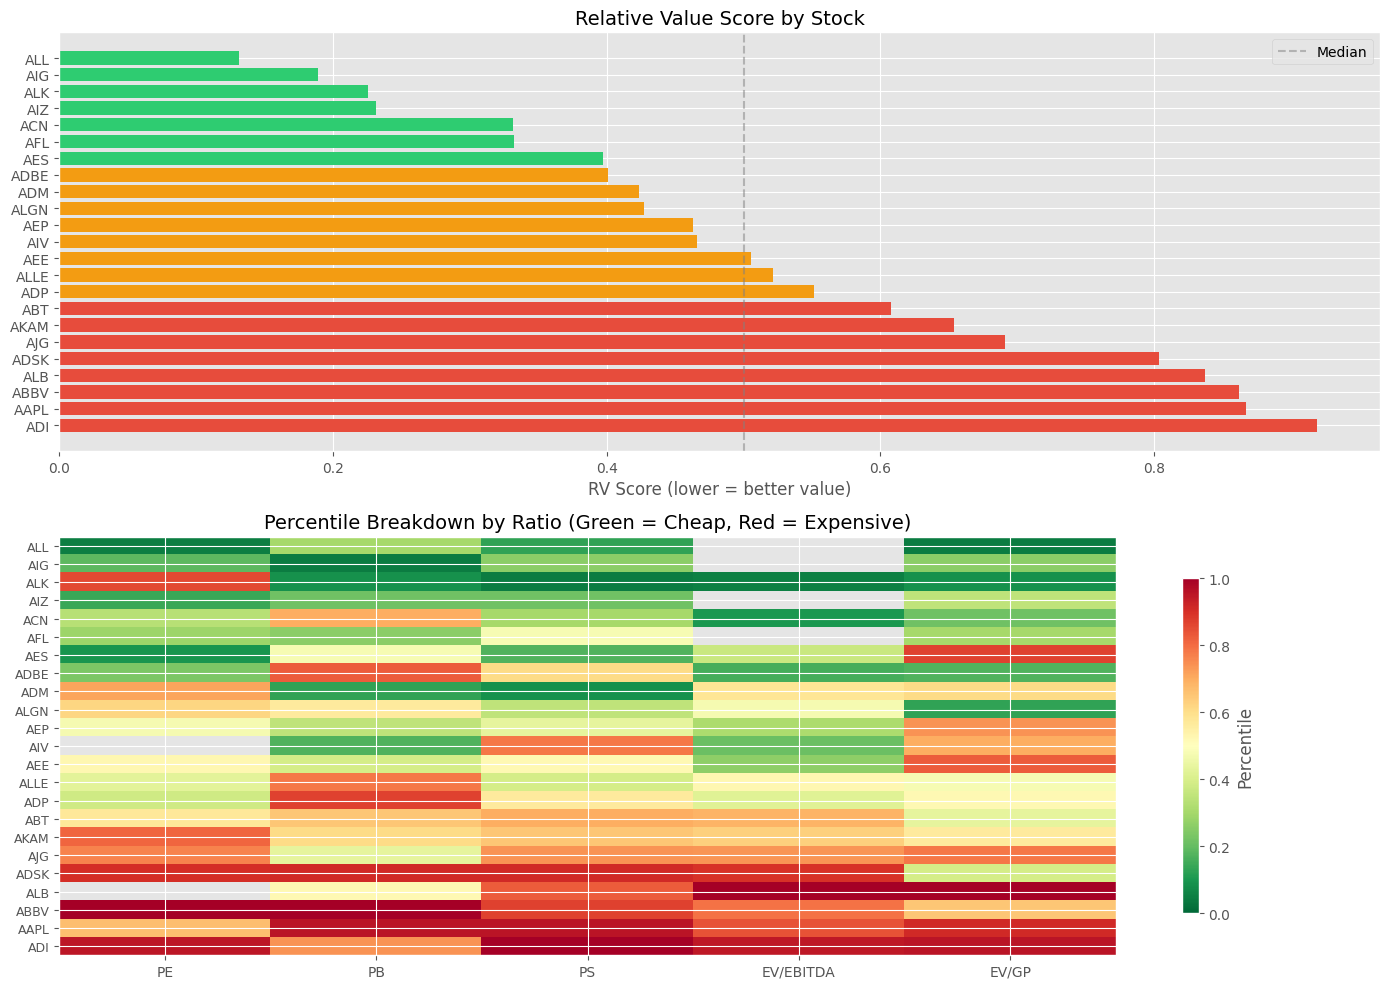

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# RV Score bar chart
colors = ['#2ecc71' if x < 0.4 else '#e74c3c' if x > 0.6 else '#f39c12' for x in final_df['RV Score']]
axes[0].barh(final_df['Ticker'], final_df['RV Score'], color=colors)
axes[0].set_xlabel('RV Score (lower = better value)')
axes[0].set_title('Relative Value Score by Stock', fontsize=14)
axes[0].invert_yaxis()
axes[0].axvline(x=0.5, color='gray', linestyle='--', alpha=0.5, label='Median')
axes[0].legend()

# Percentile breakdown heatmap
heatmap_data = final_df.set_index('Ticker')[percentile_cols]
im = axes[1].imshow(heatmap_data.values, cmap='RdYlGn_r', aspect='auto', vmin=0, vmax=1)
axes[1].set_xticks(range(len(percentile_cols)))
axes[1].set_xticklabels(['PE', 'PB', 'PS', 'EV/EBITDA', 'EV/GP'], fontsize=10)
axes[1].set_yticks(range(len(heatmap_data)))
axes[1].set_yticklabels(heatmap_data.index, fontsize=9)
axes[1].set_title('Percentile Breakdown by Ratio (Green = Cheap, Red = Expensive)', fontsize=14)
plt.colorbar(im, ax=axes[1], shrink=0.8, label='Percentile')

plt.tight_layout()
plt.savefig('../../results/value_investing_rv_scores.png', dpi=150, bbox_inches='tight')
plt.show()